In [1]:
import torch
from torchvision import transforms, datasets
from torchvision.models import efficientnet_b3,EfficientNet_B3_Weights
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim
from google.colab import drive
import zipfile

In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
#Extract dataset
zip_path = '/content/drive/MyDrive/test_images.zip'
extract_patch  = '/content/data'
with zipfile.ZipFile(zip_path,  'r') as zip_ref:
    zip_ref.extractall(extract_patch)
    print('Extracted')

Extracted


In [9]:
#Transform
transform_test = transforms.Compose([
    transforms .Resize((300,300)),
    transforms .ToTensor(),
    transforms .Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [20]:
# Datasets
test_data = datasets.ImageFolder(
    root='/content/data/New folder (3)/test_images',
    transform=transform_test
)
print(f'Test:{len(test_data)}')
test_loader = DataLoader(test_data, batch_size=32,
                         shuffle=False,num_workers=2)


Test:444


In [25]:
# model - EfficientNet B3
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

num_classes = len(test_data.classes)
model = efficientnet_b3(weights=EfficientNet_B3_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model.load_state_dict(torch.load('/content/drive/MyDrive/Project Dataset/best_model.pth',
map_location=device))


Device: cuda


<All keys matched successfully>

In [26]:
#validation
model.to(device)
model.eval()
val_correct = 0
val_total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        val_total += labels.size(0)
        val_correct += (predicted == labels).sum().item()

val_acc = 100 * val_correct / val_total
print(f'Validation Accuracy: {val_acc:.2f}%')


Validation Accuracy: 91.44%


In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns 
import matplotlib.pyplot as plt


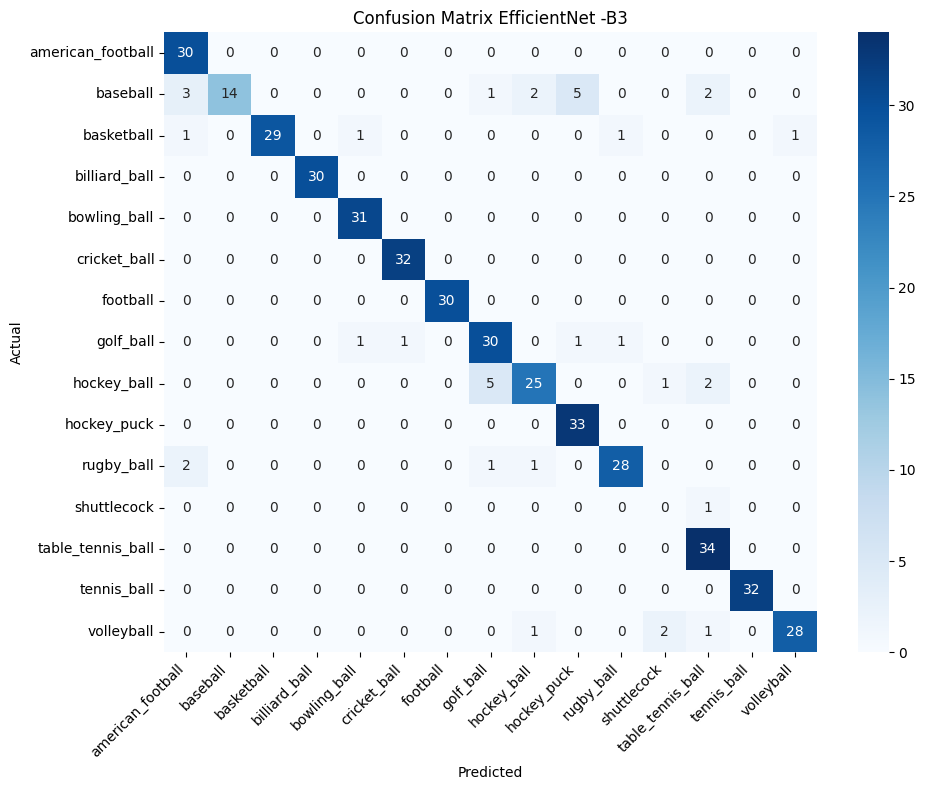

In [28]:
#predicition
model.eval()
all_labels = []
all_preds = []
with torch.no_grad():
    for images,labels in test_loader:
        images,labels = images.to(device),labels.to(device)
        outputs = model(images)
        _,predicted = torch.max(outputs,1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())
cm = confusion_matrix(all_labels,all_preds)
plt.figure(figsize=(10,8))
sns.heatmap(cm,annot=True,fmt = 'd',cmap = 'Blues',
            xticklabels=test_data.classes,
            yticklabels=test_data.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix EfficientNet -B3')
plt.xticks(rotation = 45,ha = 'right')
plt.tight_layout()
plt.show()

Classification Report:
                   precision    recall  f1-score   support

american_football       0.83      1.00      0.91        30
         baseball       1.00      0.52      0.68        27
       basketball       1.00      0.88      0.94        33
    billiard_ball       1.00      1.00      1.00        30
     bowling_ball       0.94      1.00      0.97        31
     cricket_ball       0.97      1.00      0.98        32
         football       1.00      1.00      1.00        30
        golf_ball       0.81      0.88      0.85        34
      hockey_ball       0.86      0.76      0.81        33
      hockey_puck       0.85      1.00      0.92        33
       rugby_ball       0.93      0.88      0.90        32
      shuttlecock       0.00      0.00      0.00         1
table_tennis_ball       0.85      1.00      0.92        34
      tennis_ball       1.00      1.00      1.00        32
       volleyball       0.97      0.88      0.92        32

         accuracy              

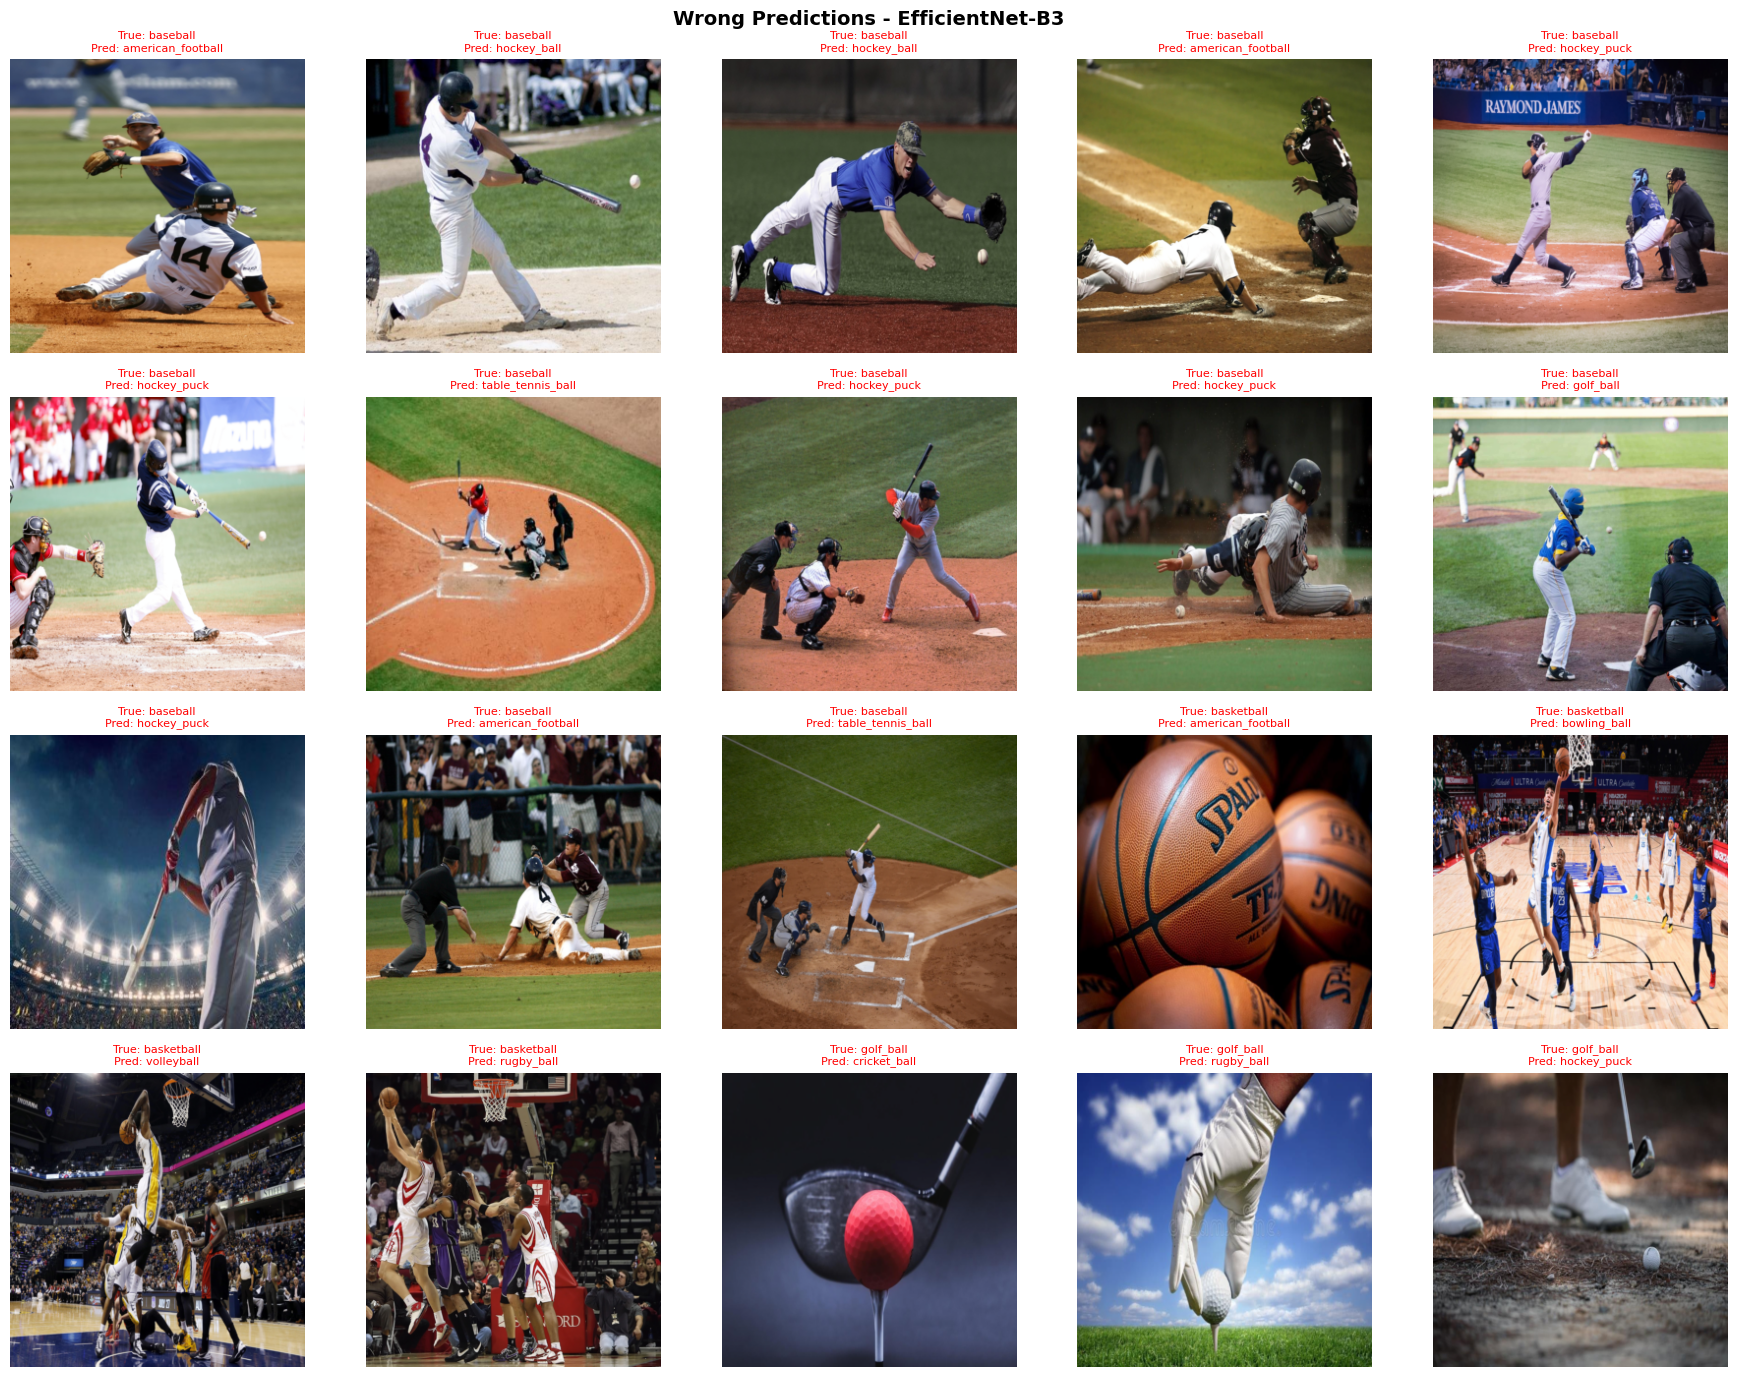


Error Count per Class:
----------------------------------------
  baseball                  -> 13 errors
  hockey_ball               -> 8 errors
  basketball                -> 4 errors
  golf_ball                 -> 4 errors
  rugby_ball                -> 4 errors
  volleyball                -> 4 errors
  shuttlecock               -> 1 errors

Top 10 Confused Class Pairs:
----------------------------------------
  baseball                  -> hockey_puck               (5 times)
  hockey_ball               -> golf_ball                 (5 times)
  baseball                  -> american_football         (3 times)
  baseball                  -> hockey_ball               (2 times)
  baseball                  -> table_tennis_ball         (2 times)
  hockey_ball               -> table_tennis_ball         (2 times)
  rugby_ball                -> american_football         (2 times)
  volleyball                -> shuttlecock               (2 times)
  baseball                  -> golf_ball       

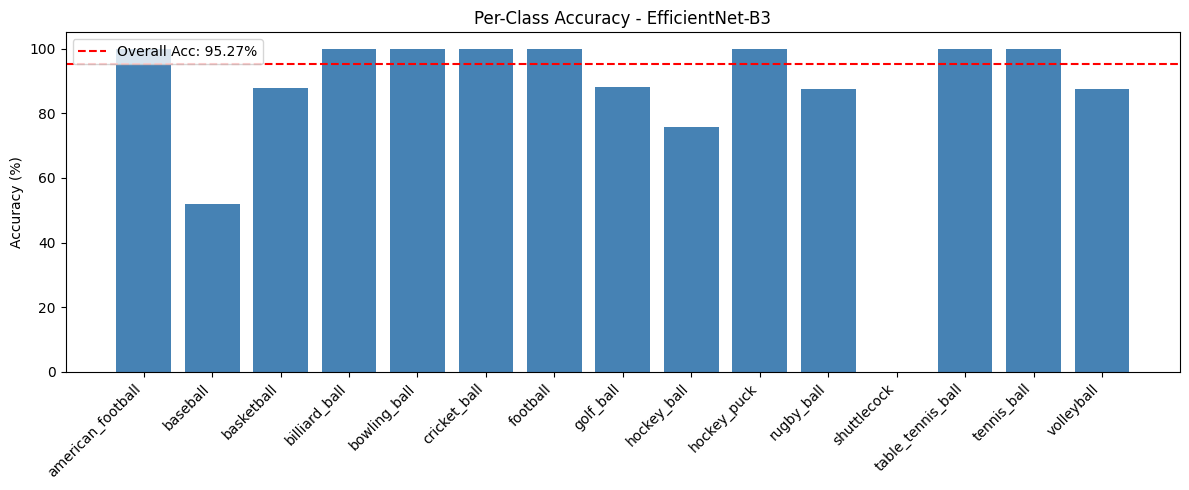

In [29]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from sklearn.metrics import classification_report

# Classification Report
print("Classification Report:")
print(classification_report(all_labels, all_preds,
                             target_names=test_data.classes))

# Wrong Predictions
model.eval()
wrong_images = []
wrong_preds = []
wrong_labels = []

mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        wrong_mask = predicted != labels
        wrong_images.extend(images[wrong_mask].cpu())
        wrong_preds.extend(predicted[wrong_mask].cpu().numpy())
        wrong_labels.extend(labels[wrong_mask].cpu().numpy())

print(f"Wrong predictions: {len(wrong_images)} / {len(test_data)}")

n_show = min(20, len(wrong_images))
fig, axes = plt.subplots(4, 5, figsize=(18, 14))
axes = axes.flatten()

for i in range(n_show):
    img = wrong_images[i].numpy().transpose(1, 2, 0)
    img = std * img + mean
    img = np.clip(img, 0, 1)

    true_cls = test_data.classes[wrong_labels[i]]
    pred_cls = test_data.classes[wrong_preds[i]]

    axes[i].imshow(img)
    axes[i].set_title(f"True: {true_cls}\nPred: {pred_cls}", fontsize=8, color='red')
    axes[i].axis('off')

for i in range(n_show, len(axes)):
    axes[i].axis('off')

plt.suptitle("Wrong Predictions - EfficientNet-B3", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Error Analysis per Class
print("\nError Count per Class:")
print("-" * 40)
label_errors = Counter(wrong_labels)
for cls_idx, count in sorted(label_errors.items(), key=lambda x: -x[1]):
    cls_name = test_data.classes[cls_idx]
    print(f"  {cls_name:<25} -> {count} errors")

print("\nTop 10 Confused Class Pairs:")
print("-" * 40)
pair_errors = Counter(zip(wrong_labels, wrong_preds))
for (true_idx, pred_idx), count in pair_errors.most_common(10):
    true_cls = test_data.classes[true_idx]
    pred_cls = test_data.classes[pred_idx]
    print(f"  {true_cls:<25} -> {pred_cls:<25} ({count} times)")

# Per-Class Accuracy Chart
class_correct = [0] * num_classes
class_total = [0] * num_classes

for true, pred in zip(all_labels, all_preds):
    class_total[true] += 1
    if true == pred:
        class_correct[true] += 1

class_acc = [100 * class_correct[i] / class_total[i] for i in range(num_classes)]

plt.figure(figsize=(12, 5))
plt.bar(test_data.classes, class_acc, color='steelblue')
plt.axhline(y=95.27, color='red', linestyle='--', label='Overall Acc: 95.27%')
plt.xticks(rotation=45, ha='right')
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy - EfficientNet-B3")
plt.legend()
plt.tight_layout()
plt.show()